# Лабораторная работа №3. Древовидные алгоритмы
**Набор:** mfeat-fac, вариант 3. **Бустинг:** GradientBoostingClassifier.


### Импорт библиотек

In [ ]:
import io
import zipfile
from urllib.request import urlopen
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

SEED = 42
GREEN, RED, PURPLE = '#228B22', '#D62728', '#8A2BE2'
COLORS = [GREEN, RED, PURPLE]
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True,
                     'grid.alpha': 0.2, 'axes.prop_cycle': plt.cycler(color=COLORS)})

## 1. Описание и подготовка данных
[UCI Multiple Features](https://archive.ics.uci.edu/dataset/72/multiple+features): 2000 рукописных цифр 0–9, по 200 объектов каждого класса. Файл **mfeat-fac** содержит 216 числовых признаков — корреляций профилей. Названия признаков условные: fac_001–fac_216. Метки восстанавливаются по порядку строк, указанному UCI; пропусков нет. Масштабирование для деревьев не требуется.


### Загрузка mfeat-fac и проверка данных

,fac_001,fac_002,fac_003,fac_004,fac_005,fac_006,fac_007,fac_008,fac_009,fac_010,...,fac_207,fac_208,fac_209,fac_210,fac_211,fac_212,fac_213,fac_214,fac_215,fac_216
0,98,236,531,673,607,647,2,9,3,6,...,474,536,628,632,18,36,8,15,12,13
1,121,193,607,611,585,665,7,9,2,4,...,520,458,570,634,15,32,11,13,15,11
2,115,141,590,605,557,627,12,6,3,3,...,535,498,572,656,20,35,16,14,13,6
3,90,122,627,692,607,642,0,6,4,5,...,576,549,628,621,16,35,7,12,15,9
4,157,167,681,666,587,666,8,6,1,4,...,594,525,568,653,16,35,10,15,13,13


Объектов: 2000, признаков: 216
Пропусков: 0, повторяющихся строк: 6


,mean,std,min,max
fac_001,272.0515,91.275454,67.0,515.0
fac_002,322.7255,109.426588,81.0,565.0
fac_003,774.8245,140.141570,500.0,1264.0
fac_004,754.3390,109.173768,543.0,1134.0
fac_005,640.4605,48.940117,437.0,823.0
...,...,...,...,...
fac_212,21.5840,7.982343,1.0,38.0
fac_213,17.6120,5.884451,1.0,36.0
fac_214,11.9680,2.579788,4.0,18.0
fac_215,13.7045,1.985485,5.0,19.0


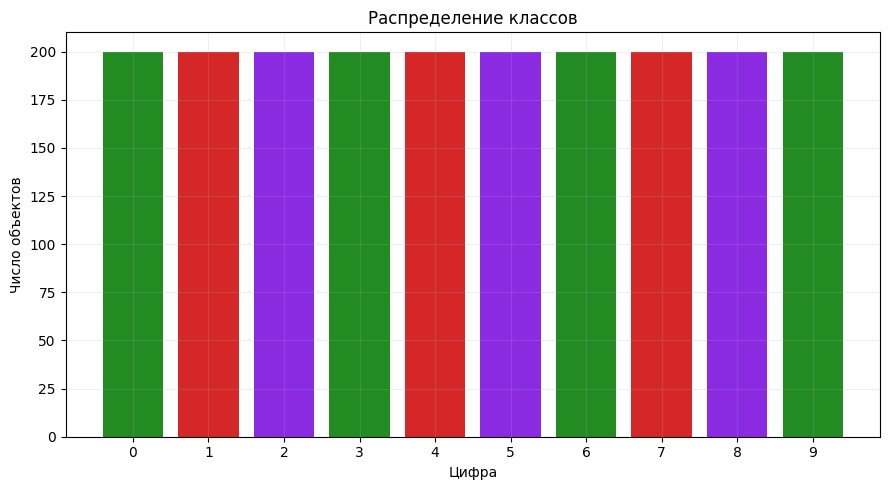

In [ ]:
URL = 'https://archive.ics.uci.edu/static/public/72/multiple+features.zip'
with urlopen(URL, timeout=60) as response:
    archive_bytes = response.read()
with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    filename = next(name for name in archive.namelist()
                    if name.split('/')[-1] == 'mfeat-fac')
    X = pd.read_csv(io.BytesIO(archive.read(filename)), sep=r'\s+', header=None)
X.columns = [f'fac_{i:03d}' for i in range(1, X.shape[1] + 1)]
y = pd.Series(np.repeat(np.arange(10), 200), name='digit')
assert X.shape == (2000, 216)
assert np.isfinite(X.to_numpy()).all()
display(X.head())
print(f'Объектов: {len(X)}, признаков: {X.shape[1]}')
print(f'Пропусков: {X.isna().sum().sum()}, повторяющихся строк: {X.duplicated().sum()}')
display(X.describe().T[['mean', 'std', 'min', 'max']])

counts = y.value_counts().sort_index()
plt.bar(counts.index, counts.values, color=[COLORS[i % 3] for i in counts.index])
plt.xticks(range(10))
plt.xlabel('Цифра'); plt.ylabel('Число объектов'); plt.title('Распределение классов')
plt.tight_layout(); plt.show()

### Разделение: обучение 60%, валидация 20%, тест 20%



In [ ]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)
print(f'Обучение: {len(X_train)}, валидация: {len(X_val)}, тест: {len(X_test)}')

def scores(model, features=None):
    columns = X.columns if features is None else features
    return {'train_accuracy': accuracy_score(y_train, model.predict(X_train[columns])),
            'val_accuracy': accuracy_score(y_val, model.predict(X_val[columns]))}

def test_scores(name, model, features=None):
    columns = X.columns if features is None else features
    prediction = model.predict(X_test[columns])
    return {'Модель': name, 'Признаков': len(columns),
            'test_accuracy': accuracy_score(y_test, prediction),
            'test_f1_macro': f1_score(y_test, prediction, average='macro')}

Обучение: 1200, валидация: 400, тест: 400


## 2. DecisionTree

### Сравнение глубины и min_samples_split, включая полное дерево

,max_depth,min_samples_split,depth_actual,leaves,train_accuracy,val_accuracy
9,None,2,18,86,1.0000,0.8900
10,None,10,14,55,0.9683,0.8825
11,None,30,13,41,0.9375,0.8625
6,8,2,8,39,0.9042,0.8525
7,8,10,8,27,0.8917,0.8500
8,8,30,8,23,0.8858,0.8450
4,5,10,5,18,0.6350,0.6025
5,5,30,5,15,0.6308,0.6000
3,5,2,5,21,0.6383,0.5975
2,3,30,3,7,0.4550,0.4300


Выбранное дерево: None min_samples_split = 2


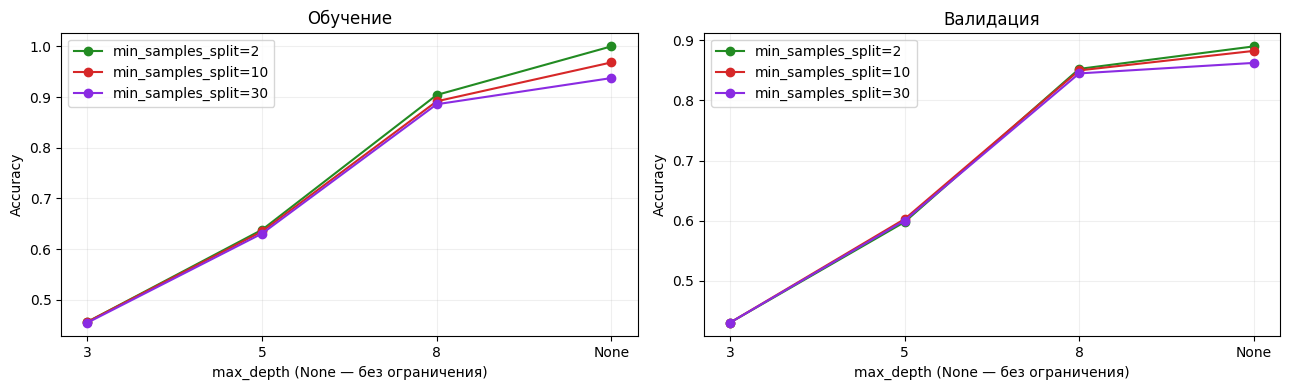

In [ ]:
depths = [3, 5, 8, None]
min_splits = [2, 10, 30]
dt_rows, dt_models = [], []
for depth, min_split in product(depths, min_splits):
    model = DecisionTreeClassifier(max_depth=depth, min_samples_split=min_split,
                                   random_state=SEED)
    model.fit(X_train, y_train)
    dt_models.append(model)
    dt_rows.append({'max_depth': str(depth), 'min_samples_split': min_split,
                    'depth_actual': model.get_depth(), 'leaves': model.get_n_leaves(),
                    **scores(model)})
dt_results = pd.DataFrame(dt_rows)
display(dt_results.sort_values('val_accuracy', ascending=False).round(4))
best_dt_index = dt_results['val_accuracy'].idxmax()
best_dt = dt_models[best_dt_index]
full_dt = dt_models[dt_results.index[(dt_results.max_depth == 'None') &
                                    (dt_results.min_samples_split == 2)][0]]
print('Выбранное дерево:', best_dt.get_params()['max_depth'],
      'min_samples_split =', best_dt.min_samples_split)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for min_split, color in zip(min_splits, COLORS):
    subset = dt_results[dt_results.min_samples_split == min_split]
    for ax, metric, title in zip(axes, ['train_accuracy', 'val_accuracy'],
                                ['Обучение', 'Валидация']):
        ax.plot(subset.max_depth, subset[metric], 'o-', color=color,
                label=f'min_samples_split={min_split}')
        ax.set(xlabel='max_depth (None — без ограничения)', ylabel='Accuracy', title=title)
        ax.legend()
plt.tight_layout(); plt.show()

## 3. Структура дерева и исключение корневого признака

### Полная текстовая структура, используемые признаки и схема дерева

Выбранное дерево решений (глубина 18, листьев 86)
|--- fac_212 <= 31.500
|   |--- fac_097 <= 294.500
|   |   |--- fac_085 <= 271.000
|   |   |   |--- fac_133 <= 370.500
|   |   |   |   |--- fac_109 <= 410.000
|   |   |   |   |   |--- fac_031 <= 18.000
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- fac_031 >  18.000
|   |   |   |   |   |   |--- fac_063 <= 619.500
|   |   |   |   |   |   |   |--- class: 8
|   |   |   |   |   |   |--- fac_063 >  619.500
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- fac_109 >  410.000
|   |   |   |   |   |--- class: 6
|   |   |   |--- fac_133 >  370.500
|   |   |   |   |--- class: 4
|   |   |--- fac_085 >  271.000
|   |   |   |--- fac_145 <= 324.500
|   |   |   |   |--- fac_017 <= 743.500
|   |   |   |   |   |--- class: 6
|   |   |   |   |--- fac_017 >  743.500
|   |   |   |   |   |--- fac_151 <= 31.000
|   |   |   |   |   |   |--- fac_209 <= 744.500
|   |   |   |   |   |   |   |--- class: 4
|   |   |   |   |   |   |--- fac

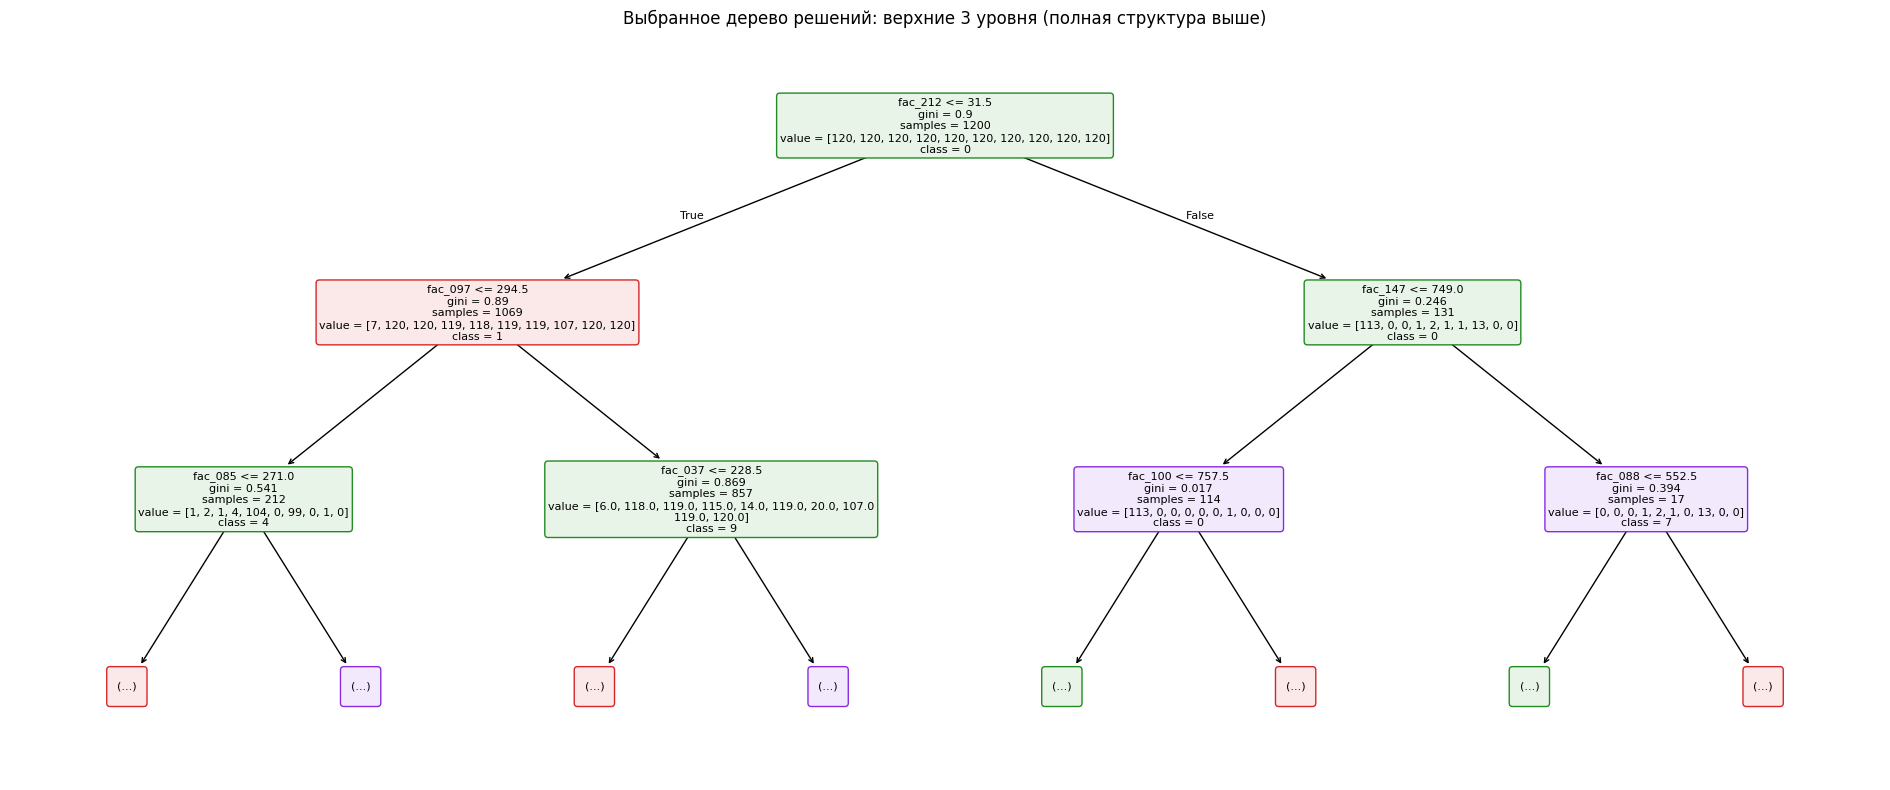

Признаки в дереве: fac_001, fac_002, fac_005, fac_006, fac_007, fac_008, fac_017, fac_018, fac_019, fac_023, fac_028, fac_031, fac_036, fac_037, fac_038, fac_044, fac_045, fac_046, fac_050, fac_055, fac_063, fac_065, fac_067, fac_068, fac_071, fac_072, fac_074, fac_075, fac_076, fac_080, fac_085, fac_086, fac_088, fac_091, fac_094, fac_097, fac_098, fac_100, fac_101, fac_102, fac_105, fac_109, fac_110, fac_113, fac_115, fac_121, fac_124, fac_125, fac_133, fac_134, fac_138, fac_145, fac_147, fac_149, fac_151, fac_158, fac_166, fac_168, fac_170, fac_174, fac_175, fac_180, fac_181, fac_184, fac_185, fac_186, fac_205, fac_208, fac_209, fac_211, fac_212
Корневой признак: fac_212


In [ ]:
def show_structure(model, title):
    # Полный текст содержит все ветвления
    print(title, f'(глубина {model.get_depth()}, листьев {model.get_n_leaves()})')
    print(export_text(model, feature_names=list(X.columns),
                      max_depth=model.get_depth(), decimals=3))
    fig, ax = plt.subplots(figsize=(19, 8))
    nodes = plot_tree(model, feature_names=list(X.columns),
                      class_names=[str(i) for i in range(10)], max_depth=2,
                      filled=False, rounded=True, fontsize=8, ax=ax)
    for i, node in enumerate(nodes):
        patch = node.get_bbox_patch()
        if patch is not None:
            patch.set_edgecolor(COLORS[i % 3])
            patch.set_facecolor(['#E9F4E9', '#FBE9E9', '#F2E9FD'][i % 3])
    ax.set_title(title + ': верхние 3 уровня (полная структура выше)')
    plt.tight_layout(); plt.show()

show_structure(best_dt, 'Выбранное дерево решений')
used_indices = np.unique(best_dt.tree_.feature[best_dt.tree_.feature >= 0])
print('Признаки в дереве:', ', '.join(X.columns[used_indices]))
root_feature = X.columns[best_dt.tree_.feature[0]]
print('Корневой признак:', root_feature)

### Boxplot корневого признака по классам и дерево без него

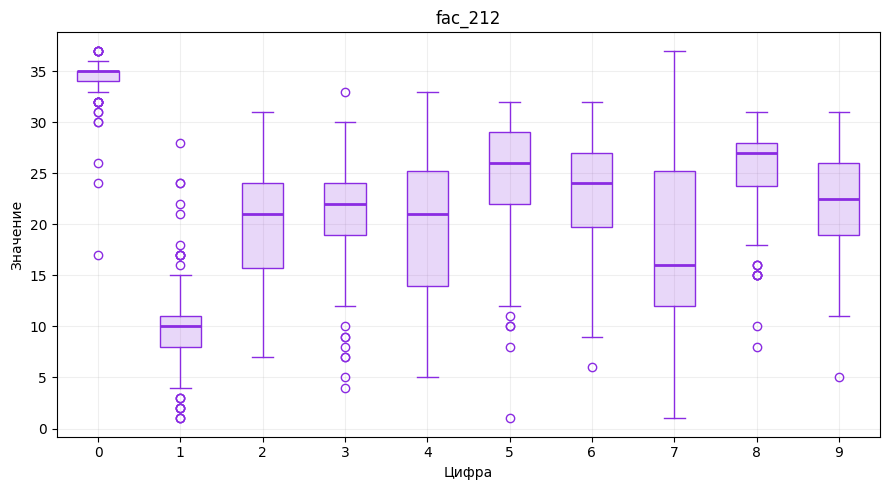

,Набор,train_accuracy,val_accuracy
0,Все признаки,1.0,0.890
1,Без fac_212,1.0,0.905


Изменение validation accuracy после исключения корня: +0.0150.
Параметры дерева сохранены, чтобы оценить влияние исключения признака.


In [ ]:
def class_boxplot(feature, ax, color):
    data = [X_train.loc[y_train == digit, feature].to_numpy() for digit in range(10)]
    boxes = ax.boxplot(data, patch_artist=True,
                        medianprops={'color': color, 'linewidth': 2},
                        whiskerprops={'color': color}, capprops={'color': color},
                        flierprops={'markeredgecolor': color})
    for patch in boxes['boxes']:
        patch.set(facecolor=color + '30', edgecolor=color)
    ax.set_xticks(range(1, 11), labels=range(10))
    ax.set(xlabel='Цифра', ylabel='Значение', title=feature)

fig, ax = plt.subplots()
class_boxplot(root_feature, ax, PURPLE)
plt.tight_layout(); plt.show()
without_root = X.columns.drop(root_feature)
dt_without_root = DecisionTreeClassifier(**best_dt.get_params())
dt_without_root.fit(X_train[without_root], y_train)
root_comparison = pd.DataFrame([
    {'Набор': 'Все признаки', **scores(best_dt)},
    {'Набор': f'Без {root_feature}', **scores(dt_without_root, without_root)}])
display(root_comparison.round(4))
delta_root = root_comparison.val_accuracy.iloc[1] - root_comparison.val_accuracy.iloc[0]
print(f'Изменение validation accuracy после исключения корня: {delta_root:+.4f}.')
print('Параметры дерева сохранены, чтобы оценить влияние исключения признака.')

## 4. RandomForest: число деревьев, число признаков и глубина

### Перебор параметров случайного леса

,n_estimators,max_features,max_depth,train_accuracy,val_accuracy
1,30,sqrt,None,1.0000,0.9775
9,100,sqrt,None,1.0000,0.9775
7,60,0.3,None,1.0000,0.9750
11,100,0.3,None,1.0000,0.9750
5,60,sqrt,None,1.0000,0.9725
3,30,0.3,None,1.0000,0.9700
4,60,sqrt,5,0.9775,0.9525
8,100,sqrt,5,0.9775,0.9500
0,30,sqrt,5,0.9783,0.9475
10,100,0.3,5,0.9633,0.9400


Выбранные параметры: {'n_estimators': 30, 'max_features': 'sqrt', 'max_depth': None}
sqrt: примерно 14 признаков на разбиение; 0.3: 64


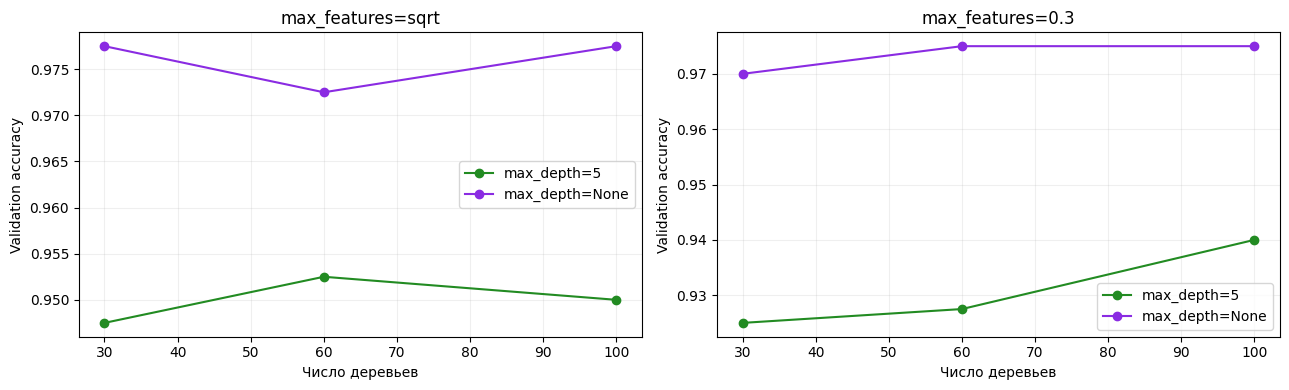

In [ ]:
rf_rows, rf_models = [], []
for n, features, depth in product([30, 60, 100], ['sqrt', 0.3], [5, None]):
    model = RandomForestClassifier(n_estimators=n, max_features=features,
                                   max_depth=depth, random_state=SEED, n_jobs=-1)
    model.fit(X_train, y_train)
    rf_models.append(model)
    rf_rows.append({'n_estimators': n, 'max_features': str(features),
                    'max_depth': str(depth), **scores(model)})
rf_results = pd.DataFrame(rf_rows)
display(rf_results.sort_values('val_accuracy', ascending=False).round(4))
best_rf = rf_models[rf_results['val_accuracy'].idxmax()]
rf_params = {name: best_rf.get_params()[name]
             for name in ['n_estimators', 'max_features', 'max_depth']}
print('Выбранные параметры:', rf_params)
print('sqrt: примерно', int(np.sqrt(X.shape[1])),
      'признаков на разбиение; 0.3:', int(0.3 * X.shape[1]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, features in zip(axes, ['sqrt', '0.3']):
    for depth, color in zip(['5', 'None'], [GREEN, PURPLE]):
        subset = rf_results[(rf_results.max_features == features) &
                            (rf_results.max_depth == depth)]
        ax.plot(subset.n_estimators, subset.val_accuracy, 'o-', color=color,
                label=f'max_depth={depth}')
    ax.set(title=f'max_features={features}', xlabel='Число деревьев',
           ylabel='Validation accuracy')
    ax.legend()
plt.tight_layout(); plt.show()

### Структура трёх деревьев выбранного случайного леса

RandomForest: дерево 1 (глубина 16, листьев 112)
|--- fac_097 <= 293.500
|   |--- fac_210 <= 610.000
|   |   |--- fac_142 <= 11.500
|   |   |   |--- fac_153 <= 27.500
|   |   |   |   |--- class: 0.0
|   |   |   |--- fac_153 >  27.500
|   |   |   |   |--- class: 1.0
|   |   |--- fac_142 >  11.500
|   |   |   |--- class: 4.0
|   |--- fac_210 >  610.000
|   |   |--- fac_067 <= 25.500
|   |   |   |--- fac_042 <= 907.000
|   |   |   |   |--- class: 4.0
|   |   |   |--- fac_042 >  907.000
|   |   |   |   |--- fac_178 <= 7.500
|   |   |   |   |   |--- class: 4.0
|   |   |   |   |--- fac_178 >  7.500
|   |   |   |   |   |--- fac_100 <= 683.500
|   |   |   |   |   |   |--- class: 8.0
|   |   |   |   |   |--- fac_100 >  683.500
|   |   |   |   |   |   |--- fac_179 <= 6.000
|   |   |   |   |   |   |   |--- class: 6.0
|   |   |   |   |   |   |--- fac_179 >  6.000
|   |   |   |   |   |   |   |--- fac_033 <= 6.500
|   |   |   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |   |   |   |--- fac_0

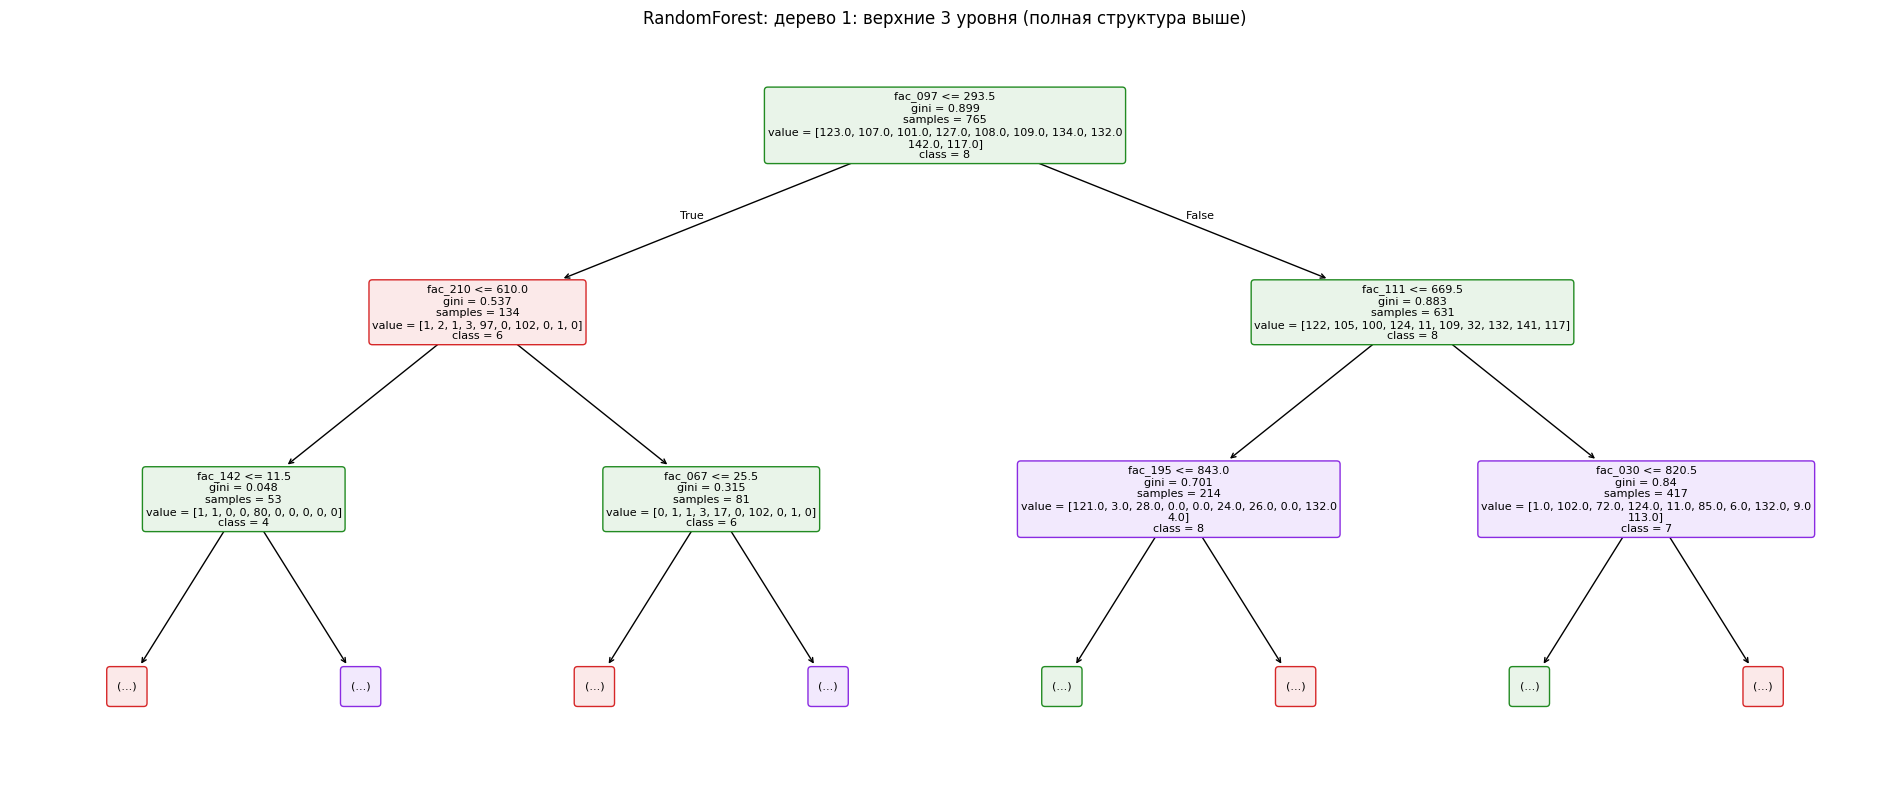

RandomForest: дерево 2 (глубина 12, листьев 96)
|--- fac_186 <= 784.000
|   |--- fac_195 <= 853.500
|   |   |--- fac_037 <= 231.000
|   |   |   |--- fac_048 <= 4.500
|   |   |   |   |--- class: 2.0
|   |   |   |--- fac_048 >  4.500
|   |   |   |   |--- fac_155 <= 15.500
|   |   |   |   |   |--- class: 3.0
|   |   |   |   |--- fac_155 >  15.500
|   |   |   |   |   |--- class: 5.0
|   |   |--- fac_037 >  231.000
|   |   |   |--- fac_094 <= 11.500
|   |   |   |   |--- fac_171 <= 619.500
|   |   |   |   |   |--- fac_013 <= 281.500
|   |   |   |   |   |   |--- fac_031 <= 27.000
|   |   |   |   |   |   |   |--- fac_163 <= 4.500
|   |   |   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |   |   |   |--- fac_163 >  4.500
|   |   |   |   |   |   |   |   |--- fac_068 <= 18.500
|   |   |   |   |   |   |   |   |   |--- fac_187 <= 2.500
|   |   |   |   |   |   |   |   |   |   |--- class: 8.0
|   |   |   |   |   |   |   |   |   |--- fac_187 >  2.500
|   |   |   |   |   |   |   |   |   |   |--- 

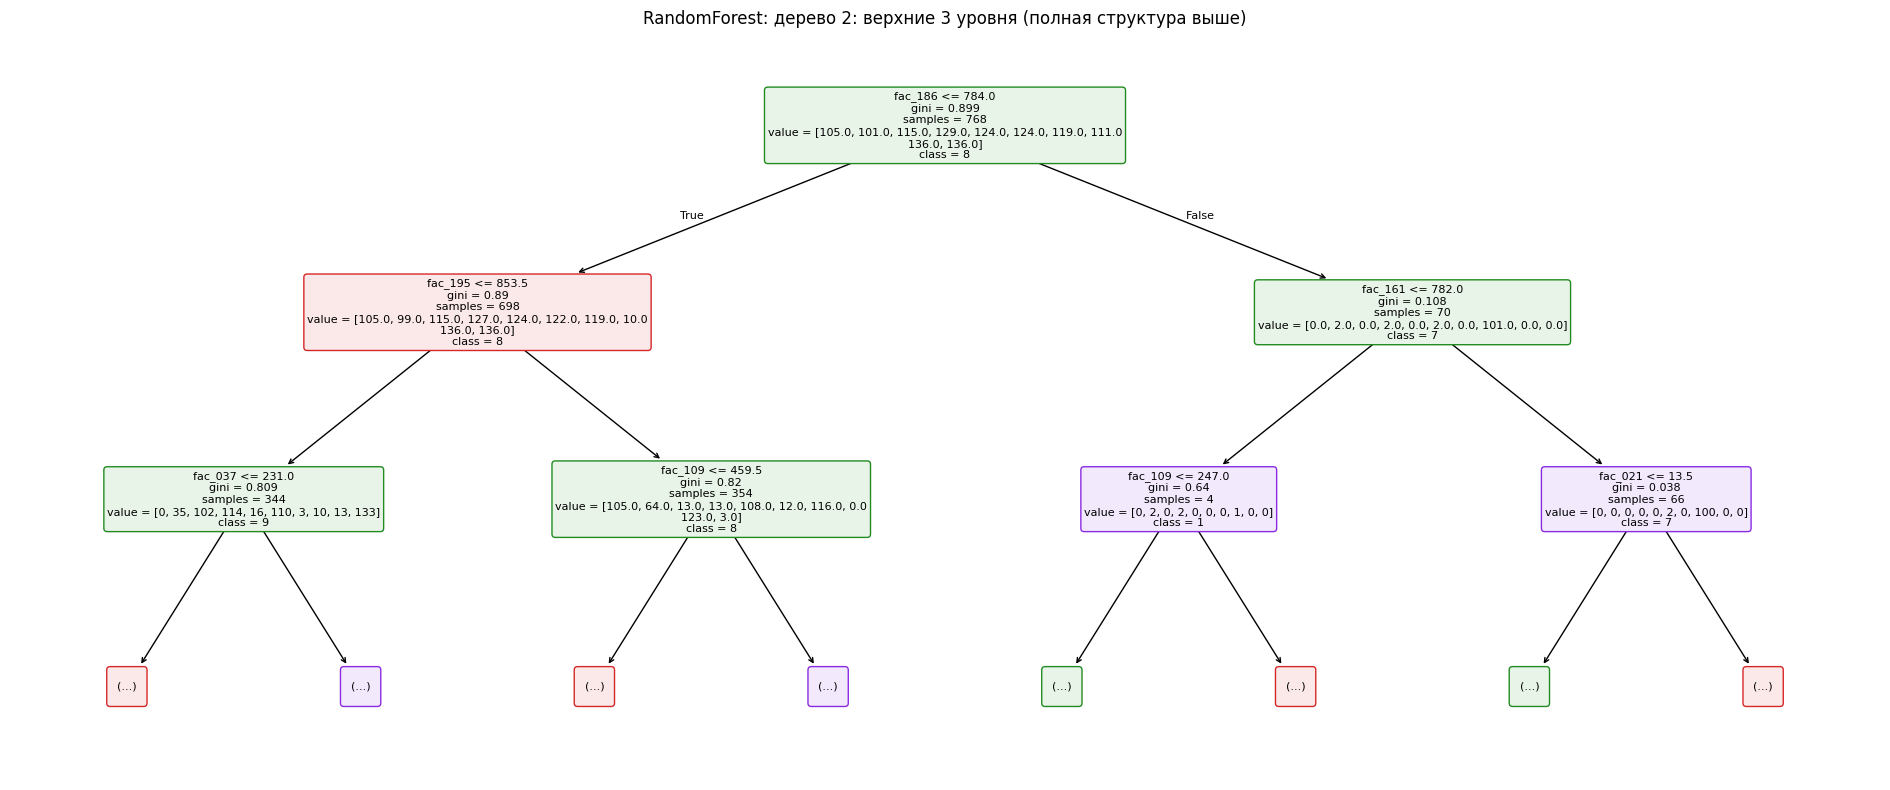

RandomForest: дерево 3 (глубина 13, листьев 99)
|--- fac_125 <= 791.500
|   |--- fac_055 <= 31.500
|   |   |--- fac_159 <= 572.500
|   |   |   |--- fac_137 <= 550.000
|   |   |   |   |--- fac_057 <= 7.000
|   |   |   |   |   |--- class: 8.0
|   |   |   |   |--- fac_057 >  7.000
|   |   |   |   |   |--- fac_002 <= 377.500
|   |   |   |   |   |   |--- class: 5.0
|   |   |   |   |   |--- fac_002 >  377.500
|   |   |   |   |   |   |--- class: 6.0
|   |   |   |--- fac_137 >  550.000
|   |   |   |   |--- fac_156 <= 14.000
|   |   |   |   |   |--- fac_182 <= 318.000
|   |   |   |   |   |   |--- class: 4.0
|   |   |   |   |   |--- fac_182 >  318.000
|   |   |   |   |   |   |--- class: 1.0
|   |   |   |   |--- fac_156 >  14.000
|   |   |   |   |   |--- fac_073 <= 292.500
|   |   |   |   |   |   |--- class: 2.0
|   |   |   |   |   |--- fac_073 >  292.500
|   |   |   |   |   |   |--- class: 9.0
|   |   |--- fac_159 >  572.500
|   |   |   |--- fac_180 <= 10.500
|   |   |   |   |--- fac_003 <= 783.

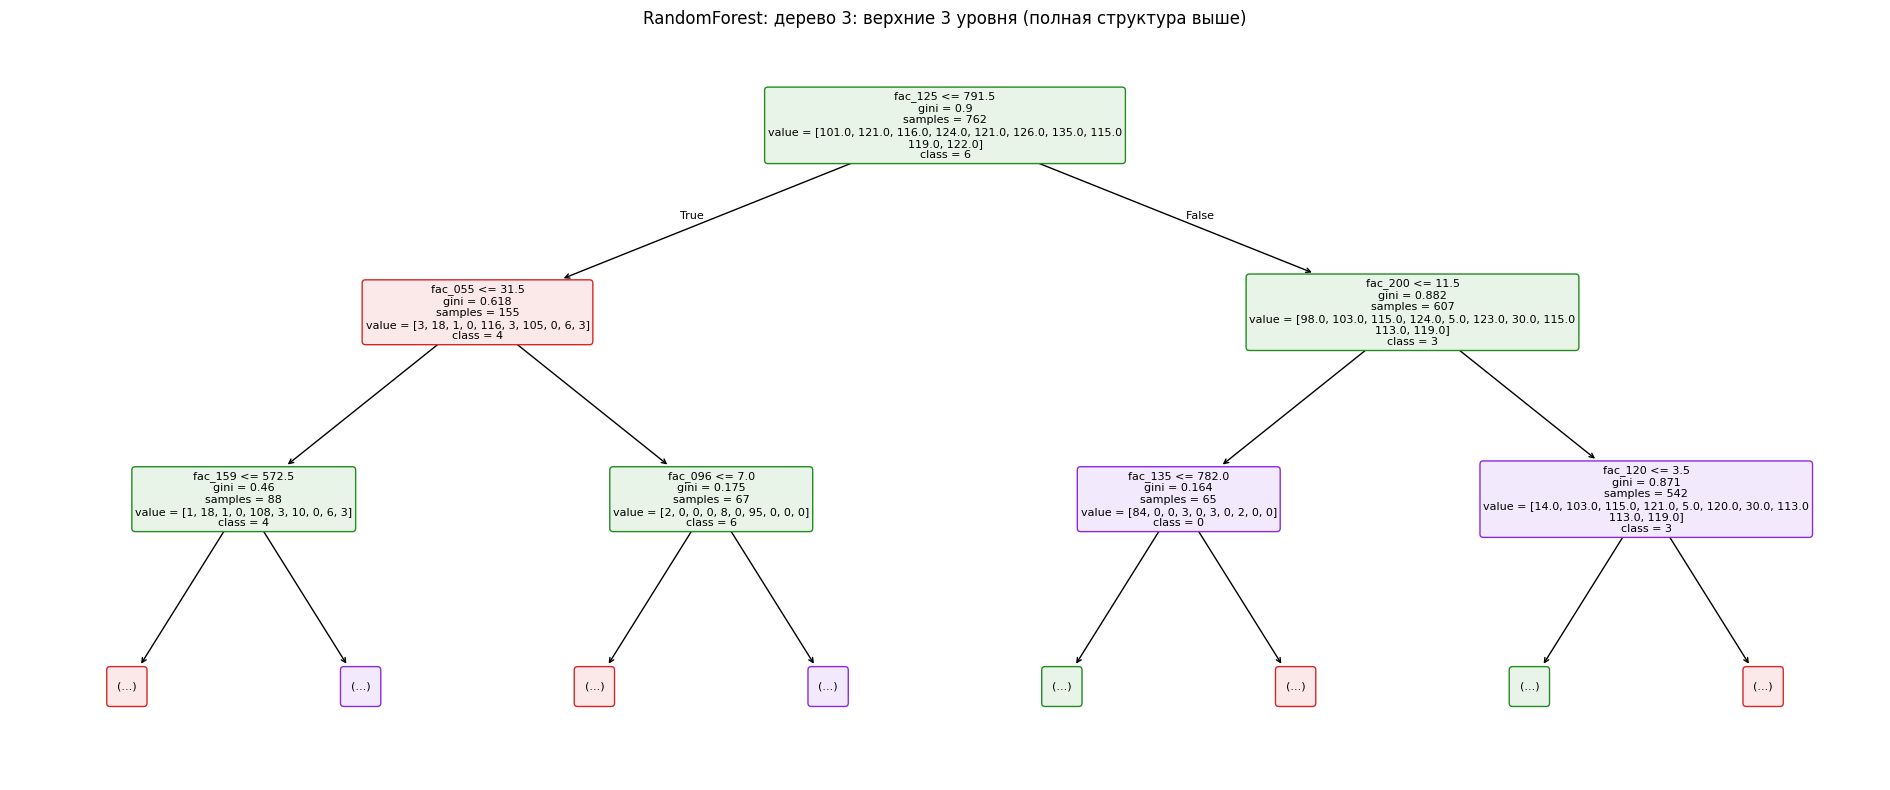

In [ ]:
for i in range(3):
    show_structure(best_rf.estimators_[i], f'RandomForest: дерево {i + 1}')

## 5. Важность признаков
Используется встроенная важность по уменьшению неоднородности узлов (MDI), рассчитанная на обучающей части.

### Важности DecisionTree и RandomForest для всех 216 признаков

,DecisionTree,RandomForest
Признак,,
fac_186,0.074154,0.030355
fac_006,0.001737,0.023767
fac_185,0.004177,0.021458
fac_181,0.002402,0.018779
fac_212,0.089093,0.018566
...,...,...
fac_023,0.001389,0.000506
fac_209,0.000926,0.000411
fac_116,0.000000,0.000320


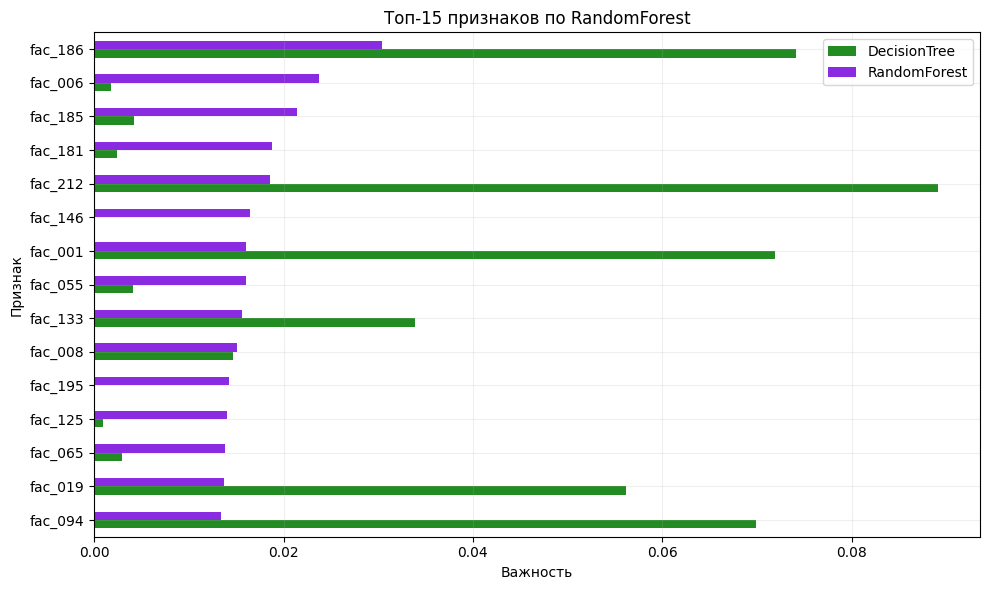

In [ ]:
importance = pd.DataFrame({'DecisionTree': best_dt.feature_importances_,
                           'RandomForest': best_rf.feature_importances_}, index=X.columns)
importance.index.name = 'Признак'
importance = importance.sort_values('RandomForest', ascending=False)
display(importance)
fig, ax = plt.subplots(figsize=(10, 6))
importance.head(15).iloc[::-1].plot.barh(ax=ax, color=[GREEN, PURPLE])
ax.set(xlabel='Важность', title='Топ-15 признаков по RandomForest')
plt.tight_layout(); plt.show()

### Boxplot трёх наиболее важных признаков RandomForest по классам

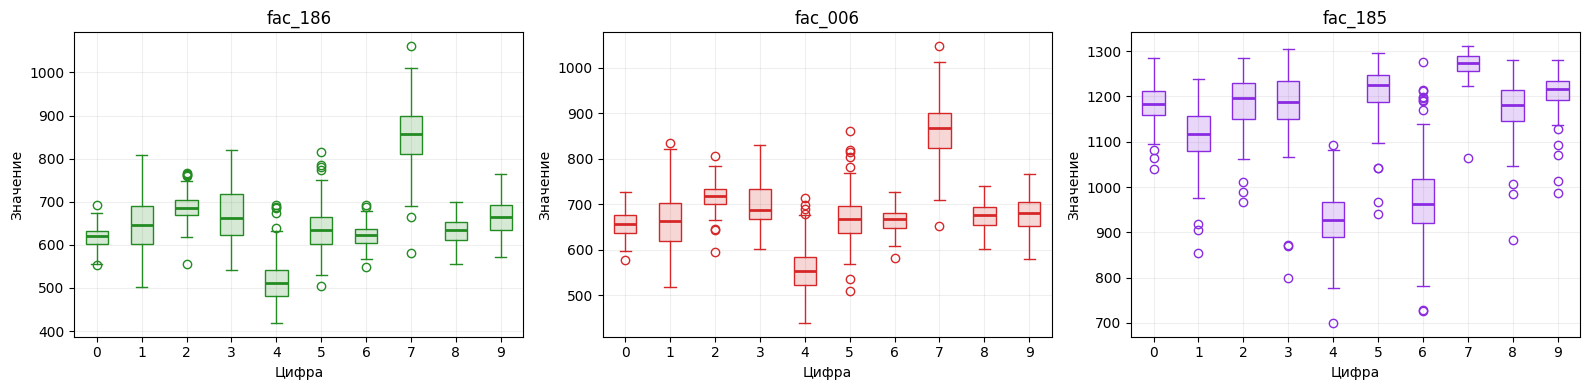

Три наиболее важных признака: fac_186, fac_006, fac_185


In [ ]:
top3 = importance.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for feature, ax, color in zip(top3, axes, COLORS):
    class_boxplot(feature, ax, color)
plt.tight_layout(); plt.show()
print('Три наиболее важных признака:', ', '.join(top3))

## 6. RandomForest на разных наборах признаков
30% от 216 округляем вверх: 65 признаков. Ранжирование взято только из обучающей части; параметры моделей одинаковы.

### Обучение лесов на полном наборе, лучших и худших 30% признаков

,Набор,Признаков,train_accuracy,val_accuracy
0,Все признаки,216,1.0,0.9775
1,Лучшие 30%,65,1.0,0.9650
2,Худшие 30%,65,1.0,0.9425


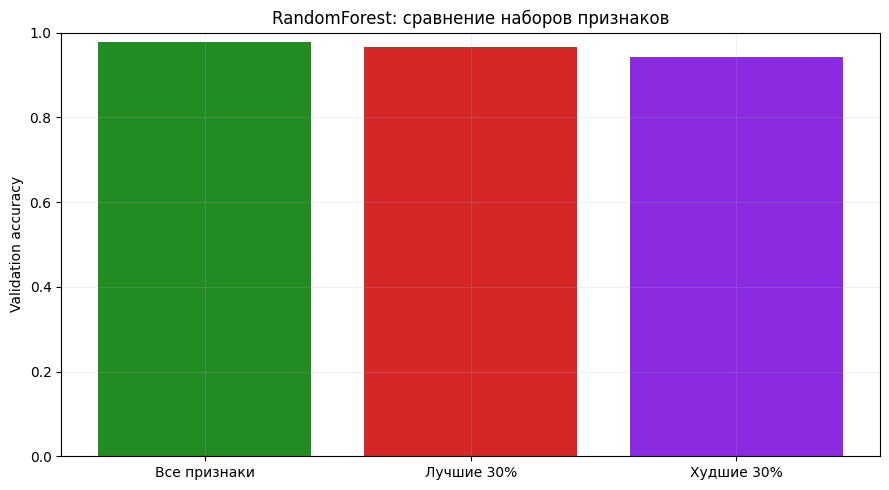

In [ ]:
k = int(np.ceil(0.3 * X.shape[1]))
feature_sets = {'Все признаки': list(X.columns),
                'Лучшие 30%': list(importance.index[:k]),
                'Худшие 30%': list(importance.index[-k:])}
rf_subset_models = {'Все признаки': best_rf}
subset_rows = []
for name, columns in feature_sets.items():
    if name != 'Все признаки':
        model = RandomForestClassifier(**best_rf.get_params())
        model.fit(X_train[columns], y_train)
        rf_subset_models[name] = model
    subset_rows.append({'Набор': name, 'Признаков': len(columns),
                        **scores(rf_subset_models[name], columns)})
subset_results = pd.DataFrame(subset_rows)
display(subset_results.round(4))
plt.bar(subset_results['Набор'], subset_results.val_accuracy, color=COLORS)
plt.ylim(0, 1); plt.ylabel('Validation accuracy')
plt.title('RandomForest: сравнение наборов признаков')
plt.tight_layout(); plt.show()

## 7. GradientBoosting: влияние числа деревьев
Базовые деревья имеют max_depth=3 (три уровня разбиений). Для 10 классов каждая итерация строит 10 деревьев; n_estimators задаёт число итераций.

### GradientBoosting и качество на разных этапах бустинга

,n_estimators,Число деревьев,train_accuracy,val_accuracy
0,10,100,0.9842,0.9325
1,25,250,1.0000,0.9575
2,50,500,1.0000,0.9625
3,75,750,1.0000,0.9600
4,100,1000,1.0000,0.9575


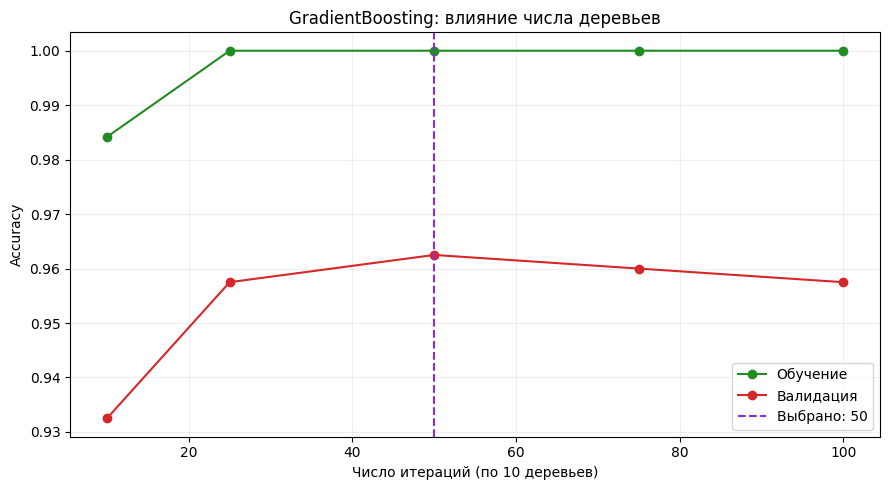

По валидации выбрано 50 итераций, то есть 500 деревьев.


In [ ]:
gb = GradientBoostingClassifier(n_estimators=100, max_depth=3,
                                learning_rate=0.1, random_state=SEED)
gb.fit(X_train, y_train)
stages = [10, 25, 50, 75, 100]
gb_rows = []
for n, (train_pred, val_pred) in enumerate(zip(
        gb.staged_predict(X_train), gb.staged_predict(X_val)), start=1):
    if n in stages:
        gb_rows.append({'n_estimators': n, 'Число деревьев': n * len(gb.classes_),
                        'train_accuracy': accuracy_score(y_train, train_pred),
                        'val_accuracy': accuracy_score(y_val, val_pred)})
gb_results = pd.DataFrame(gb_rows)
display(gb_results.round(4))
best_n = int(gb_results.loc[gb_results.val_accuracy.idxmax(), 'n_estimators'])
best_gb = GradientBoostingClassifier(n_estimators=best_n, max_depth=3,
                                     learning_rate=0.1, random_state=SEED)
best_gb.fit(X_train, y_train)
plt.plot(gb_results.n_estimators, gb_results.train_accuracy, 'o-', color=GREEN,
         label='Обучение')
plt.plot(gb_results.n_estimators, gb_results.val_accuracy, 'o-', color=RED,
         label='Валидация')
plt.axvline(best_n, color=PURPLE, linestyle='--', label=f'Выбрано: {best_n}')
plt.xlabel('Число итераций (по 10 деревьев)'); plt.ylabel('Accuracy')
plt.title('GradientBoosting: влияние числа деревьев'); plt.legend()
plt.tight_layout(); plt.show()
print(f'По валидации выбрано {best_n} итераций, то есть {best_n * 10} деревьев.')

### Итоговая оценка всех моделей на отложенном тесте

,Модель,Признаков,test_accuracy,test_f1_macro
0,DecisionTree: полное,216,0.8600,0.8602
1,DecisionTree: выбранное,216,0.8600,0.8602
2,DecisionTree: без корня,215,0.8675,0.8677
3,RandomForest: Все признаки,216,0.9575,0.9573
4,RandomForest: Лучшие 30%,65,0.9400,0.9398
5,RandomForest: Худшие 30%,65,0.9275,0.9274
6,GradientBoosting,216,0.9350,0.9345


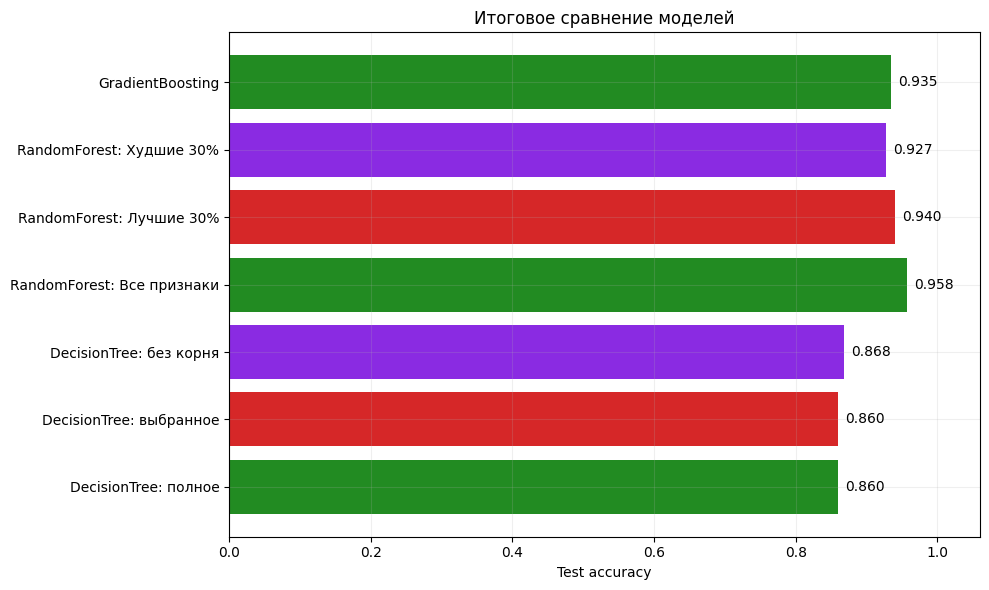

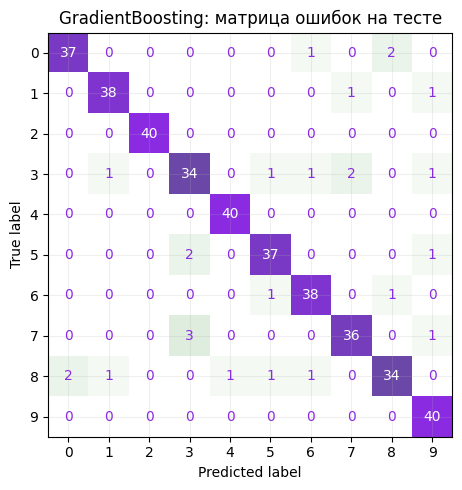

In [ ]:
final_rows = [test_scores('DecisionTree: полное', full_dt),
              test_scores('DecisionTree: выбранное', best_dt),
              test_scores('DecisionTree: без корня', dt_without_root, without_root)]
for name, model in rf_subset_models.items():
    final_rows.append(test_scores('RandomForest: ' + name, model, feature_sets[name]))
final_rows.append(test_scores('GradientBoosting', best_gb))
final_results = pd.DataFrame(final_rows)
display(final_results.round(4))

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(final_results['Модель'], final_results.test_accuracy,
        color=[COLORS[i % 3] for i in range(len(final_results))])
ax.set(xlim=(0, 1.06), xlabel='Test accuracy', title='Итоговое сравнение моделей')
for i, value in enumerate(final_results.test_accuracy):
    ax.text(value + 0.01, i, f'{value:.3f}', va='center')
plt.tight_layout(); plt.show()

cmap = LinearSegmentedColormap.from_list('lab_colors', ['white', GREEN, PURPLE])
ConfusionMatrixDisplay.from_estimator(best_gb, X_test, y_test, cmap=cmap,
                                      colorbar=False, values_format='d')
plt.title('GradientBoosting: матрица ошибок на тесте')
plt.tight_layout(); plt.show()

### Краткие выводы по результатам запуска

In [ ]:
full_row = dt_results[(dt_results.max_depth == 'None') & (dt_results.min_samples_split == 2)].iloc[0]
selected_row = dt_results.loc[best_dt_index]
print(f'Дерево: validation accuracy полного = {full_row.val_accuracy:.3f}, '
      f'выбранного = {selected_row.val_accuracy:.3f}.')
print(f'Разрыв train/validation полного дерева: '
      f'{full_row.train_accuracy - full_row.val_accuracy:.3f}.')
print(f'Исключение {root_feature}: изменение validation accuracy {delta_root:+.3f}.')
print('Лес, выбранные параметры:', rf_params)
for name in feature_sets:
    row = final_results[final_results['Модель'] == 'RandomForest: ' + name].iloc[0]
    print(f'Лес — {name}: {row["Признаков"]} признаков, test accuracy = {row.test_accuracy:.3f}.')
first, last = gb_results.iloc[0], gb_results.iloc[-1]
print(f'Бустинг: при {int(first.n_estimators)} / {int(last.n_estimators)} итерациях '
      f'validation accuracy = {first.val_accuracy:.3f} / {last.val_accuracy:.3f}.')
gb_test = final_results[final_results['Модель'] == 'GradientBoosting'].iloc[0]
print(f'Выбранный GradientBoosting: {best_n} итераций, '
      f'test accuracy = {gb_test.test_accuracy:.3f}, F1 macro = {gb_test.test_f1_macro:.3f}.')
print('Оценки важности относительные: слабые по MDI признаки могут содержать '
      'полезную информацию из-за корреляций между признаками.')

Дерево: validation accuracy полного = 0.890, выбранного = 0.890.
Разрыв train/validation полного дерева: 0.110.
Исключение fac_212: изменение validation accuracy +0.015.
Лес, выбранные параметры: {'n_estimators': 30, 'max_features': 'sqrt', 'max_depth': None}
Лес — Все признаки: 216 признаков, test accuracy = 0.958.
Лес — Лучшие 30%: 65 признаков, test accuracy = 0.940.
Лес — Худшие 30%: 65 признаков, test accuracy = 0.927.
Бустинг: при 10 / 100 итерациях validation accuracy = 0.932 / 0.958.
Выбранный GradientBoosting: 50 итераций, test accuracy = 0.935, F1 macro = 0.935.
Оценки важности относительные: слабые по MDI признаки могут содержать полезную информацию из-за корреляций между признаками.
